# FastText

In this notebook, the candidates are ranked based on their similarity to the target job title.

The job titles are converted into embeddings using a pre-trained FastText model.

The cosine similarity is used to calcualte the similarity between the vectors.

In [1]:
# import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import fasttext
from gensim.models import KeyedVectors
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
# remove limit of column display width so full job titles can be viewed
pd.set_option('display.max_colwidth', None)

In [3]:
# import the cleaned data from CSV file
data = pd.read_csv("../data/potential_talents_cleaned.csv")

In [4]:
# use the pre-trained 300-dimensional FastText Wiki News vector file
model_file = "../models/wiki-news-300d-1M.vec"
# load the first 200,000 word embeddings
fasttext_vectors = KeyedVectors.load_word2vec_format(model_file, binary=False, limit=200000)

In [5]:
# create a function to use the pre-defined model to generate word embeddings from some text
def get_sentence_embedding(text, model):
    # tokenise the input text using regex
    words = re.findall(r'\b\w+\b', str(text))

    # retrieve the FastText word embeddings for words that exist in the model's vocabulary
    word_vectors = [
        model[word]
        for word in words
        if word in model
    ]

    # if no words exist in the model, return a 0 vector
    if len(word_vectors) == 0:
        return np.zeros(model.vector_size)

    # calculate the mean of all word vectors to produce a single sentence embedding
    return np.mean(word_vectors, axis=0)

In [6]:
# define the target job title
target_title = "aspiring hr"
# get sentence embedding for target
target_embedding = get_sentence_embedding(target_title, fasttext_vectors)

In [8]:
# get sentence embeddings for candidate job titles
candidate_embeddings = np.array([
    get_sentence_embedding(title, fasttext_vectors)
    for title in data['job_title']
])

In [9]:
# find the cosine similarities between the target and each candidate
similarities = cosine_similarity(
    target_embedding.reshape(1, -1),
    candidate_embeddings
).flatten()

# add similarities to the data
data['fasttext_similarity'] = similarities
# create a column the ranks the candidates based on these similarities
data['fasttext_rank'] = data['fasttext_similarity'].rank(ascending=False, method='min').astype(int)

In [11]:
# display
data[['job_title', 'manual_score', 'fasttext_rank', 'fasttext_similarity']].sort_values(by='fasttext_rank', ascending=True)

,job_title,manual_score,fasttext_rank,fasttext_similarity
2,aspiring hr professional,5,1,0.939657
45,aspiring hr professional,5,1,0.939657
5,aspiring hr specialist,5,3,0.929684
21,aspiring hr manager seeking internship in hr,5,4,0.890636
22,hr professional,4,5,0.853242
12,aspiring hr management student seeking an internship,5,6,0.821358
6,student at humber college and aspiring hr generalist,5,7,0.813004
14,experienced retail manager and aspiring hr professional,5,8,0.808752
48,aspiring hr manager graduating may 2020 seeking an entry level hr position in st louis,5,9,0.808721
13,seeking hr opportunities,5,10,0.789882


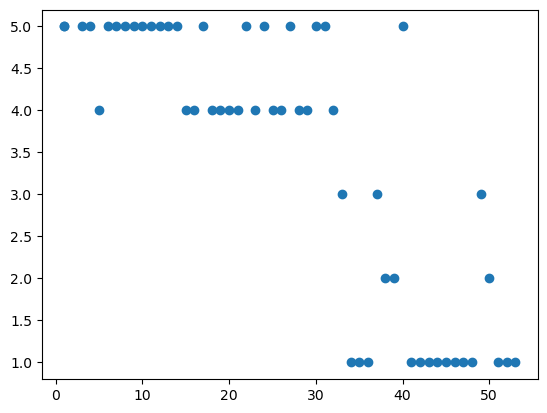

In [12]:
# compare how FastText has ranked the candidates vs the manual score assigned
data = data.sort_values(by='fasttext_rank', ascending=True)

x = data['fasttext_rank']
y = data['manual_score']

plt.scatter(x, y)